# Figure: Forward Pipeline Step-by-Step

Visualises each stage of the forward model applied to a recovered TXM sample,
using the per-image weights learned during optimization.

Pipeline: `TXM → window → neg-log → unsharp(σ_h) → clip → unsharp(σ) → clip`

**Requires:** `nb_run.ipynb`

Output: `build/processed_windowing_fwd_image.png`

In [3]:
%%capture
import os, subprocess, sys

IN_COLAB = "COLAB_GPU" in os.environ or "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")

    REPO = "/content/drive/MyDrive/Reconstruction"  # <-- repo location on Drive

    os.chdir(f"{REPO}/figures")
else:
    REPO = os.path.abspath("..")

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", REPO])
if REPO not in sys.path:
    sys.path.insert(0, REPO)



[notice] A new release of pip is available: 25.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [4]:
import sys, os, glob, joblib

import numpy as np
import matplotlib.pyplot as plt
from chest_xray_sim.inverse import operators as ops

# Fixed pipeline hyperparameters (match the conf used in nb_run.ipynb)
SIGMA      = 1.0
HIGH_SIGMA = 10.0

def load_results(results_dir="results"):
    hits = sorted(glob.glob(f"{results_dir}/*/imgs.joblib"))
    if not hits:
        raise FileNotFoundError(f"No results in '{results_dir}'. Run nb_run.ipynb first.")
    d = os.path.dirname(hits[-1])
    print(f"Loading from {d}")
    return {
        "txm":     joblib.load(f"{d}/txm.joblib"),
        "weights": joblib.load(f"{d}/weights.joblib"),
    }

/Volumes/T7/projs/thesis/.venv_nb/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
r = load_results()
txm, weights = r["txm"], r["weights"]

IDX = 0  # which image to visualise
txm_i = txm[IDX]
w = {k: float(v[IDX]) for k, v in weights.items()}
print("Learned weights for this image:")
for k, v in w.items():
    print(f"  {k}: {v:.4f}")

Loading from results/a8107d9
Learned weights for this image:
  enhance_factor: 0.5428
  gamma: 5.0181
  high_enhance_factor: 0.2530
  window_center: 0.3045
  window_width: 0.2482


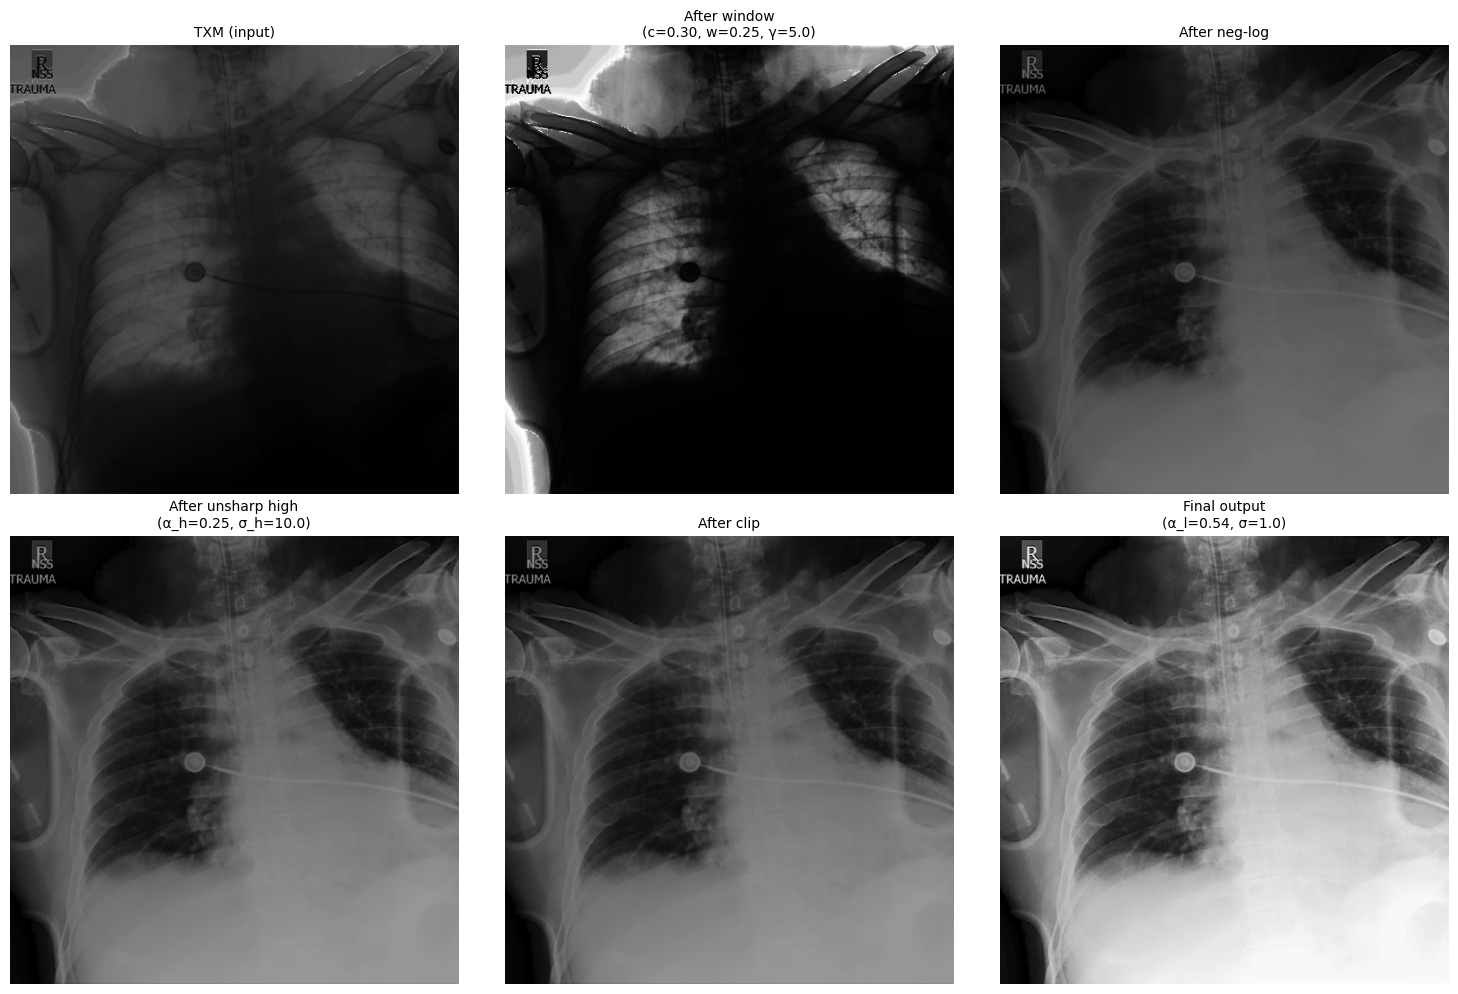

In [6]:
# Step-by-step forward pass
x0 = txm_i
x1 = ops.window(x0, w["window_center"], w["window_width"], w.get("gamma", 5.0))
x2 = ops.negative_log(x1)
x3 = ops.unsharp_masking(x2, HIGH_SIGMA, w["high_enhance_factor"])
x4 = ops.clipping(x3)
x5 = ops.unsharp_masking(x4, SIGMA, w["enhance_factor"])
x6 = ops.clipping(x5)

steps = [
    (x0, "TXM (input)"),
    (x1, f"After window\n(c={w['window_center']:.2f}, w={w['window_width']:.2f}, γ={w.get('gamma', 5.):.1f})"),
    (x2, "After neg-log"),
    (x3, f"After unsharp high\n(α_h={w['high_enhance_factor']:.2f}, σ_h={HIGH_SIGMA})"),
    (x4, "After clip"),
    (x6, f"Final output\n(α_l={w['enhance_factor']:.2f}, σ={SIGMA})"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (img, title) in zip(axes.flat, steps):
    ax.imshow(np.asarray(img), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.tight_layout()
fig.savefig("build/processed_windowing_fwd_image.png", bbox_inches="tight")
plt.show()

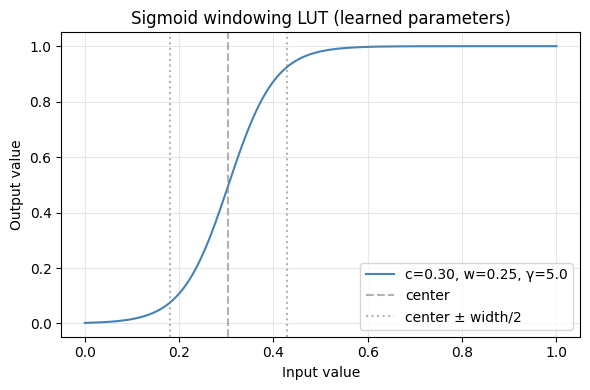

In [7]:
# Also show the sigmoid windowing LUT with the actual learned parameters
values = np.linspace(0, 1, 500)
c, ww, g = w["window_center"], w["window_width"], w.get("gamma", 5.0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(values, ops.window(values, c, ww, g), color="steelblue",
        label=f"c={c:.2f}, w={ww:.2f}, γ={g:.1f}")
ax.axvline(x=c,         color="gray", linestyle="--", alpha=0.6, label="center")
ax.axvline(x=c + ww/2, color="gray", linestyle=":",  alpha=0.6, label="center ± width/2")
ax.axvline(x=c - ww/2, color="gray", linestyle=":",  alpha=0.6)
ax.set_xlabel("Input value")
ax.set_ylabel("Output value")
ax.set_title("Sigmoid windowing LUT (learned parameters)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("build/windowing_lut_learned.png", bbox_inches="tight")
plt.show()